In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [5]:
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

In [6]:
df = pd.DataFrame(X, columns=feature_names)
df['species'] = [target_names[i] for i in y]

In [7]:
print("Dataset shape:", X.shape)
print("\nFeature names:", feature_names)
print("\nTarget names:", target_names)
print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (150, 4)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names: ['setosa' 'versicolor' 'virginica']

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


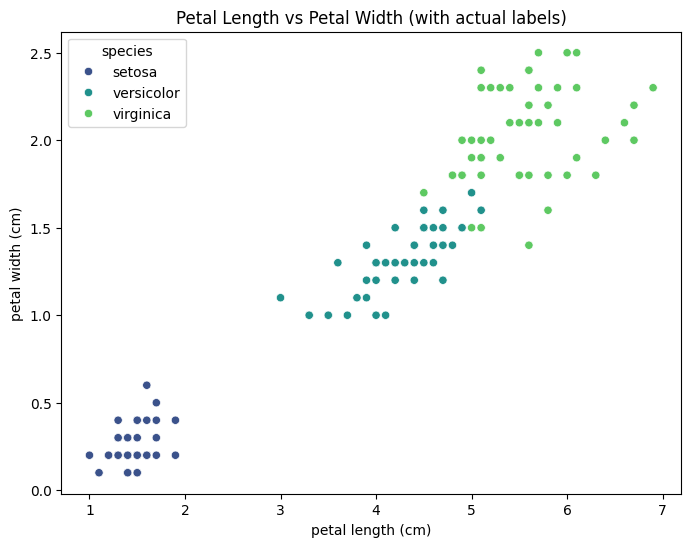

In [8]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='petal length (cm)', y='petal width (cm)',
                hue='species', data=df, palette='viridis')
plt.title('Petal Length vs Petal Width (with actual labels)')
plt.show()

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
print("Original data (first 5 rows):")
print(X[:5])


Original data (first 5 rows):
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


In [11]:
print("\nScaled data (first 5 rows):")
print(X_scaled[:5])


Scaled data (first 5 rows):
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [12]:
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [13]:
inertia

[600.0,
 222.36170496502302,
 191.02473685317958,
 114.35407164049778,
 91.04766991109526,
 81.55075699571756,
 80.77773933734285,
 64.42674849482273,
 55.70690047933695,
 51.121095396505545]

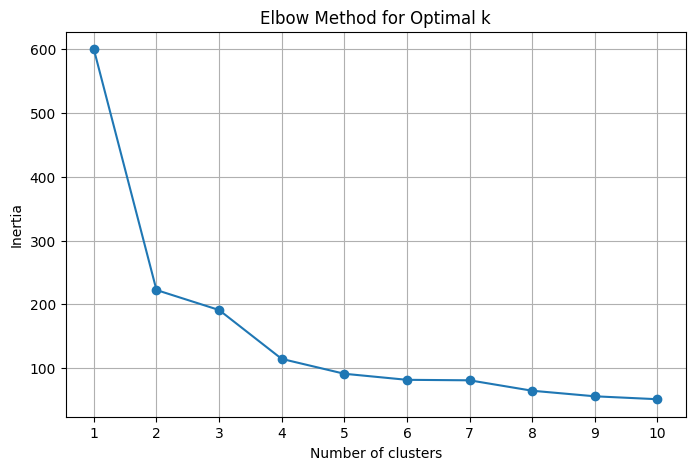

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [15]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)


In [16]:
df['cluster'] = clusters

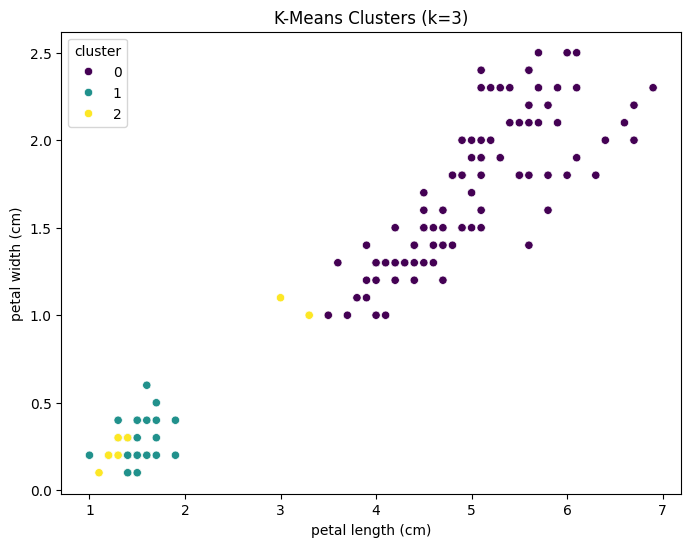

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='petal length (cm)', y='petal width (cm)',
                hue='cluster', data=df, palette='viridis')
plt.title('K-Means Clusters (k=3)')
plt.show()

In [22]:
silhouette_avg = silhouette_score(X_scaled, clusters)
print("\nSilhouette Score:", silhouette_avg)

if silhouette_avg > 0.7:
    print("Strong structure")
elif silhouette_avg > 0.5:
    print("Reasonable structure")
elif silhouette_avg > 0.25:
    print("Weak structure")
else:
    print("No substantial structure")


Silhouette Score: 0.4798814508199817
Weak structure



Cluster vs Species:
cluster      0   1   2
species               
setosa       0  33  17
versicolor  46   0   4
virginica   50   0   0


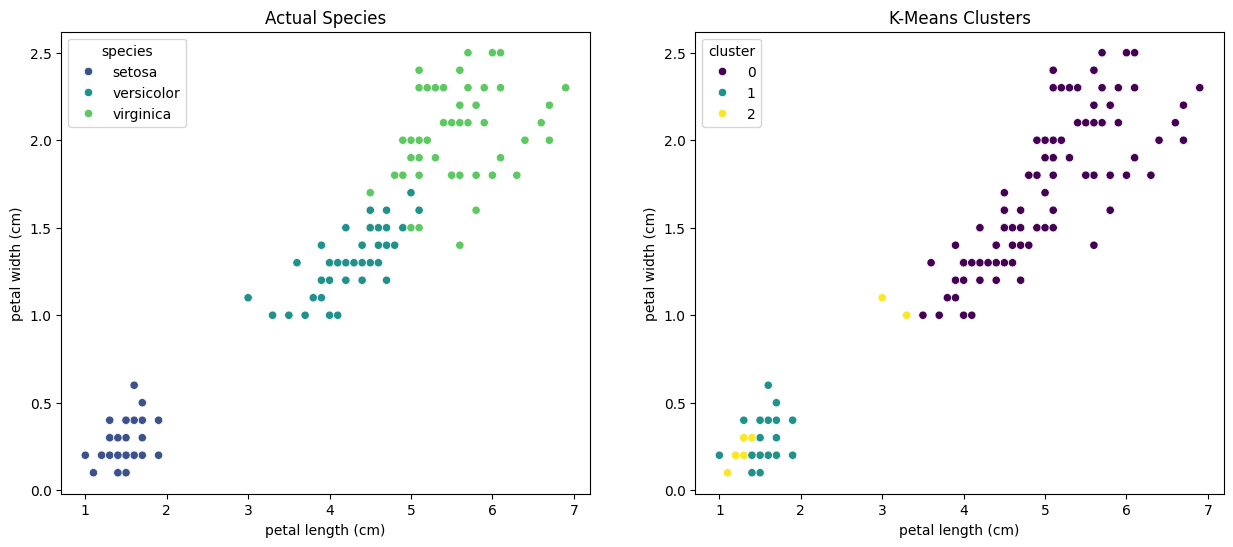

In [19]:
ct = pd.crosstab(df['species'], df['cluster'])
print("\nCluster vs Species:")
print(ct)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='petal length (cm)', y='petal width (cm)',
                hue='species', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Actual Species')
sns.scatterplot(x='petal length (cm)', y='petal width (cm)',
                hue='cluster', data=df, ax=axes[1], palette='viridis')
axes[1].set_title('K-Means Clusters')
plt.show()